# 01 - Exploratory Data Analysis (EDA)
## WELFake Dataset - Fake News Classification

**Objective:** Understand the dataset structure, check data quality, and explore patterns.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 100)

## 1. Load Dataset

In [5]:
df = pd.read_csv('../data/raw/WELFake_Dataset.csv')
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (72134, 4)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMat...,No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMat...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CHARLOTTE RIOTERS WERE “PEACEFUL” PROTESTERS…In...,"Now, most of the demonstrators gathered last night were exercising their constitutional and pro...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential...",A dozen politically active pastors came here for a private dinner Friday night to hear a convers...,0
4,4,SATAN 2: Russia unvelis an image of its terrifying new ‘SUPERNUKE’ – Western world takes notice,"The RS-28 Sarmat missile, dubbed Satan 2, will replace the SS-18 Flies at 4.3 miles (7km) per se...",1


## 2. Basic Info

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


In [7]:
df.describe()

,Unnamed: 0,label
count,72134.000000,72134.000000
mean,36066.500000,0.514404
std,20823.436496,0.499796
min,0.000000,0.000000
25%,18033.250000,0.000000
50%,36066.500000,1.000000
75%,54099.750000,1.000000
max,72133.000000,1.000000


In [8]:
# Check columns
print('Columns:', df.columns.tolist())
print('\nDtypes:')
print(df.dtypes)

Columns: ['Unnamed: 0', 'title', 'text', 'label']

Dtypes:
Unnamed: 0     int64
title         object
text          object
label          int64
dtype: object


## 3. Missing Values

In [9]:
# Missing values count and percentage
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Count': missing, 'Percentage': missing_pct})
print(missing_df)

            Count  Percentage
Unnamed: 0      0    0.000000
title         558    0.773560
text           39    0.054066
label           0    0.000000


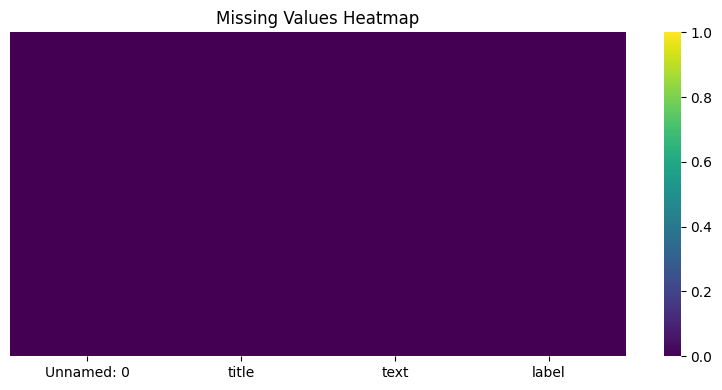

In [10]:
# Visualize missing values
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=True, yticklabels=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.tight_layout()
plt.show()

## 4. Duplicate Rows

In [11]:
duplicates = df.duplicated().sum()
print(f'Duplicate rows: {duplicates}')
print(f'Percentage: {duplicates / len(df) * 100:.2f}%')

Duplicate rows: 0
Percentage: 0.00%


## 5. Target Distribution (Label)

In [12]:
print('Label distribution:')
print(df['label'].value_counts())
print(f'\nPercentage:')
print(df['label'].value_counts(normalize=True) * 100)

Label distribution:
label
1    37106
0    35028
Name: count, dtype: int64

Percentage:
label
1    51.440375
0    48.559625
Name: proportion, dtype: float64


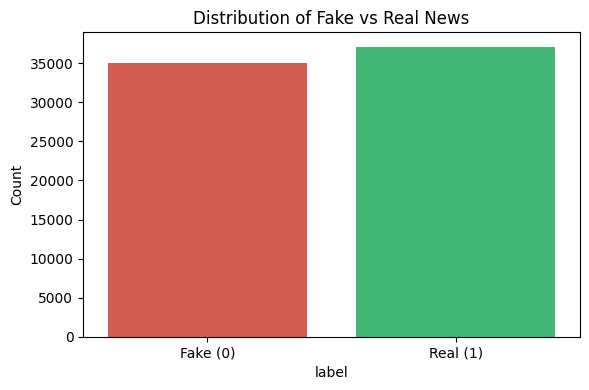

In [13]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df, palette=['#e74c3c', '#2ecc71'])
ax.set_xticklabels(['Fake (0)', 'Real (1)'])
plt.title('Distribution of Fake vs Real News')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 6. Text Length Analysis

In [14]:
# Text length (character count)
df['text_length'] = df['text'].astype(str).apply(len)
df['title_length'] = df['title'].astype(str).apply(len)

# Word count
df['text_word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))
df['title_word_count'] = df['title'].astype(str).apply(lambda x: len(x.split()))

print('Text Length Stats:')
print(df[['text_length', 'title_length', 'text_word_count', 'title_word_count']].describe())

Text Length Stats:
         text_length  title_length  text_word_count  title_word_count
count   72134.000000  72134.000000     72134.000000      72134.000000
mean     3268.324646     76.566016       540.551460         12.181052
std      3732.646914     25.768536       625.399283          4.234335
min         1.000000      1.000000         0.000000          1.000000
25%      1377.000000     61.000000       227.000000          9.000000
50%      2424.000000     73.000000       398.000000         12.000000
75%      4059.000000     89.000000       667.000000         14.000000
max    142961.000000    456.000000     24234.000000         72.000000


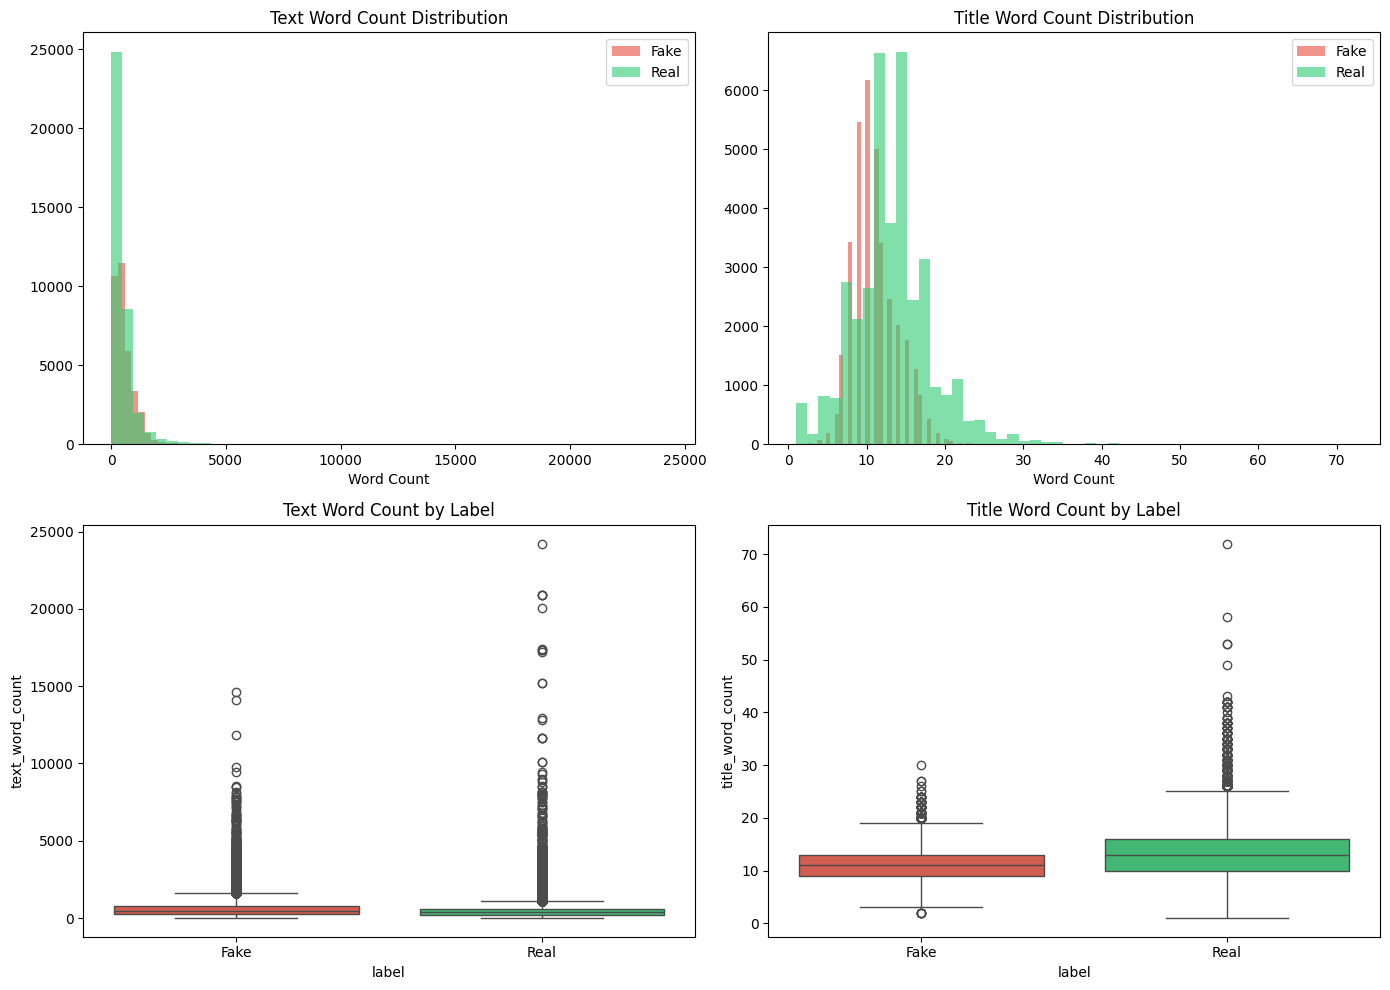

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Text length by label
for label, color in zip([0, 1], ['#e74c3c', '#2ecc71']):
    subset = df[df['label'] == label]
    axes[0, 0].hist(subset['text_word_count'], bins=50, alpha=0.6, color=color,
                     label=f"{'Fake' if label == 0 else 'Real'}")
axes[0, 0].set_title('Text Word Count Distribution')
axes[0, 0].set_xlabel('Word Count')
axes[0, 0].legend()

# Title length by label
for label, color in zip([0, 1], ['#e74c3c', '#2ecc71']):
    subset = df[df['label'] == label]
    axes[0, 1].hist(subset['title_word_count'], bins=50, alpha=0.6, color=color,
                     label=f"{'Fake' if label == 0 else 'Real'}")
axes[0, 1].set_title('Title Word Count Distribution')
axes[0, 1].set_xlabel('Word Count')
axes[0, 1].legend()

# Boxplot text length
sns.boxplot(x='label', y='text_word_count', data=df, palette=['#e74c3c', '#2ecc71'], ax=axes[1, 0])
axes[1, 0].set_title('Text Word Count by Label')
axes[1, 0].set_xticklabels(['Fake', 'Real'])

# Boxplot title length
sns.boxplot(x='label', y='title_word_count', data=df, palette=['#e74c3c', '#2ecc71'], ax=axes[1, 1])
axes[1, 1].set_title('Title Word Count by Label')
axes[1, 1].set_xticklabels(['Fake', 'Real'])

plt.tight_layout()
plt.show()

## 7. Sample Data

In [16]:
print('=== Sample FAKE news ===')
print(df[df['label'] == 0]['text'].iloc[0][:500])
print('\n' + '='*60)
print('\n=== Sample REAL news ===')
print(df[df['label'] == 1]['text'].iloc[0][:500])

=== Sample FAKE news ===
A dozen politically active pastors came here for a private dinner Friday night to hear a conversion story unique in the context of presidential politics: how Louisiana Gov. Bobby Jindal traveled from Hinduism to Protestant Christianity and, ultimately, became what he calls an “evangelical Catholic.”

Over two hours, Jindal, 42, recalled talking with a girl in high school who wanted to “save my soul,” reading the Bible in a closet so his parents would not see him and feeling a stir while watching


=== Sample REAL news ===
No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others on a radio show Tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in America.One of the F***YoFlag organizers is called  Sunshine.  She has a radio blog show hosted from Texas called,  S

## 8. Key Findings

Summarize your observations here after running the notebook:
- Dataset shape and size
- Missing values in which columns
- Class balance (Fake vs Real)
- Text length differences between Fake and Real
- Any data quality issues found

In [17]:
# Clean up temporary columns
df.drop(columns=['text_length', 'title_length', 'text_word_count', 'title_word_count'], inplace=True)